<a href="https://colab.research.google.com/github/maureljean55/atelier-saint-honore/blob/main/notebooks/q7_kmeans.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

clients = pd.read_csv("sample_data/client_propre.csv")
print("clients :", clients.shape)

clients : (679, 13)


In [3]:
clients["carte_fidelite"].value_counts()

,count
carte_fidelite,
aucune,336
argent,242
or,101


In [4]:
clients.groupby("carte_fidelite")[["anciennete_mois", "nb_achats_12m", "panier_moyen_eur", "montant_total_eur", "est_revenu_6m"]].mean().round(2)

,anciennete_mois,nb_achats_12m,panier_moyen_eur,montant_total_eur,est_revenu_6m
carte_fidelite,,,,,
argent,31.18,3.55,2655.64,12681.48,0.43
aucune,31.60,3.69,2568.83,12338.66,0.39
or,27.65,3.79,2859.57,13600.25,0.41


In [5]:
cols = ["anciennete_mois", "nb_achats_12m", "panier_moyen_eur"]

clients[cols].agg(["min", "max", "mean", "std"]).round(1)

,anciennete_mois,nb_achats_12m,panier_moyen_eur
min,1.0,1.0,290.0
max,116.0,17.0,12685.0
mean,30.9,3.7,2643.0
std,24.4,2.9,1882.6


In [6]:
X = StandardScaler().fit_transform(clients[cols])

pd.DataFrame(X, columns=cols).agg(["mean", "std"]).round(2)

,anciennete_mois,nb_achats_12m,panier_moyen_eur
mean,-0.0,0.0,0.0
std,1.0,1.0,1.0


In [7]:
clusters_brut = KMeans(n_clusters=3, n_init=10, random_state=42).fit_predict(clients[cols])

clients.groupby(clusters_brut)[cols].mean().round(1)

,anciennete_mois,nb_achats_12m,panier_moyen_eur
0,37.8,3.0,1648.9
1,14.0,8.7,7618.2
2,19.8,3.6,3342.8


In [8]:
resultats = []
inertie_prec = None

for k in range(1, 9):
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X)
    inertie = km.inertia_
    gain = round(inertie_prec - inertie, 1) if inertie_prec is not None else None
    sil = round(silhouette_score(X, km.labels_), 3) if k >= 2 else None
    resultats.append({
        "k": k,
        "inertie": round(inertie, 1),
        "gain": gain,
        "silhouette": sil
    })
    inertie_prec = inertie

resultats_k = pd.DataFrame(resultats)
resultats_k

,k,inertie,gain,silhouette
0,1,2037.0,NaN,NaN
1,2,1138.5,898.5,0.561
2,3,647.4,491.0,0.458
3,4,548.3,99.1,0.450
4,5,463.4,85.0,0.324
5,6,411.2,52.1,0.270
6,7,371.5,39.8,0.274
7,8,334.0,37.4,0.278


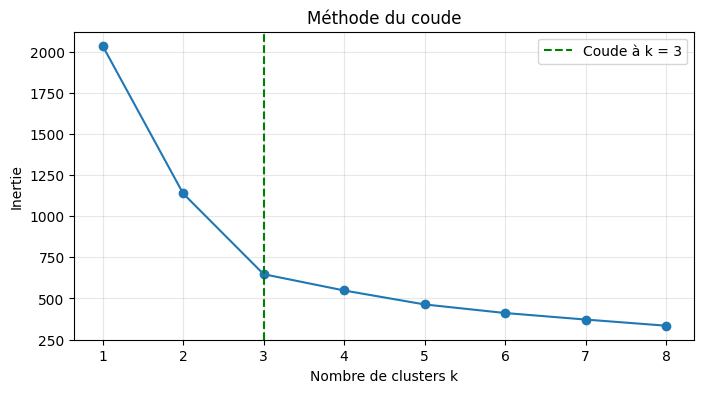

In [9]:
plt.figure(figsize=(8, 4))
plt.plot(resultats_k["k"], resultats_k["inertie"], marker="o")
plt.axvline(3, color="green", linestyle="--", label="Coude à k = 3")
plt.xlabel("Nombre de clusters k")
plt.ylabel("Inertie")
plt.title("Méthode du coude")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

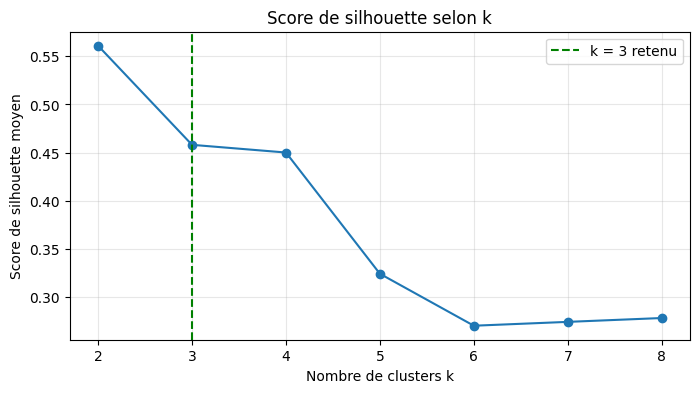

In [10]:
plt.figure(figsize=(8, 4))
plt.plot(resultats_k["k"], resultats_k["silhouette"], marker="o")
plt.axvline(3, color="green", linestyle="--", label="k = 3 retenu")
plt.xlabel("Nombre de clusters k")
plt.ylabel("Score de silhouette moyen")
plt.title("Score de silhouette selon k")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [11]:
clients["cluster"] = KMeans(n_clusters=3, n_init=10, random_state=42).fit_predict(X)

clients["cluster"].value_counts().sort_index()

,count
cluster,
0,93
1,367
2,219


In [12]:
profils = clients.groupby("cluster").agg(
    nb_clients=("client_id", "count"),
    anciennete_mois=("anciennete_mois", "mean"),
    nb_achats_12m=("nb_achats_12m", "mean"),
    panier_moyen_eur=("panier_moyen_eur", "mean"),
    retours=("retours", "mean"),
    demandes_sav=("demandes_sav", "mean"),
    taux_retour_pct=("est_revenu_6m", "mean")
)

profils["taux_retour_pct"] = profils["taux_retour_pct"] * 100
profils.round(1).sort_values("panier_moyen_eur")

,nb_clients,anciennete_mois,nb_achats_12m,panier_moyen_eur,retours,demandes_sav,taux_retour_pct
cluster,,,,,,,
2,219,61.4,3.5,1752.0,0.3,0.4,47.5
1,367,16.7,2.3,2221.0,0.4,0.4,31.9
0,93,15.0,9.4,6406.7,1.3,0.3,61.3


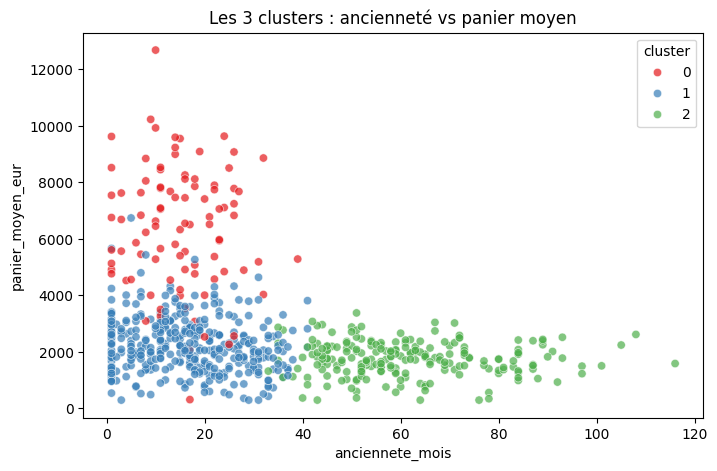

In [13]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=clients, x="anciennete_mois", y="panier_moyen_eur", hue="cluster", palette="Set1", alpha=0.7)
plt.title("Les 3 clusters : ancienneté vs panier moyen")
plt.show()

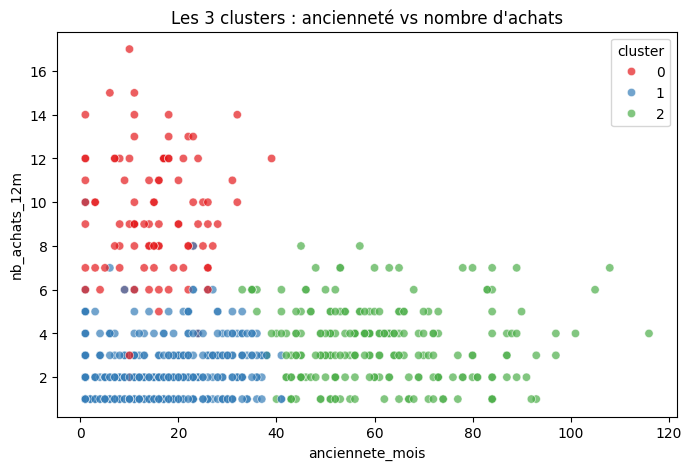

In [14]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=clients, x="anciennete_mois", y="nb_achats_12m", hue="cluster", palette="Set1", alpha=0.7)
plt.title("Les 3 clusters : ancienneté vs nombre d'achats")
plt.show()

In [15]:
pd.crosstab(clients["cluster"], clients["carte_fidelite"])

carte_fidelite,argent,aucune,or
cluster,,,
0,30,46,17
1,134,178,55
2,78,112,29


In [16]:
noms = {
    0: "Gros acheteurs VIP",
    1: "Occasionnels récents",
    2: "Fidèles historiques"
}

clients["profil"] = clients["cluster"].map(noms)

tableau_final = clients.groupby("profil").agg(
    nb_clients=("client_id", "count"),
    anciennete_mois=("anciennete_mois", "mean"),
    nb_achats_12m=("nb_achats_12m", "mean"),
    panier_moyen_eur=("panier_moyen_eur", "mean"),
    taux_retour_pct=("est_revenu_6m", "mean")
)

tableau_final["part_clients_pct"] = tableau_final["nb_clients"] / len(clients) * 100
tableau_final["taux_retour_pct"] = tableau_final["taux_retour_pct"] * 100
tableau_final.round(1).sort_values("panier_moyen_eur")

,nb_clients,anciennete_mois,nb_achats_12m,panier_moyen_eur,taux_retour_pct,part_clients_pct
profil,,,,,,
Fidèles historiques,219,61.4,3.5,1752.0,47.5,32.3
Occasionnels récents,367,16.7,2.3,2221.0,31.9,54.1
Gros acheteurs VIP,93,15.0,9.4,6406.7,61.3,13.7
